# 05 — Strategy Deep Dive

Equity curves vs SPY, rolling Sharpe and rolling returns, drawdown
periods (what happened in the worst weeks?), HRP vs equal-weight weight
evolution, turnover and cost decomposition, and the long-short leg
breakdown.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import data as data_mod
from src import features as feat_mod
from src import models as models_mod
from src import simulate as sim_mod
from src.target import make_target, time_split

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (10, 5)

# Same parameters as the fuller main.py run (50 tickers, 5 years).
# Downloads are cached under data/ (7-day freshness), so re-running is fast.
tickers = data_mod.get_universe(n=50)
prices = data_mod.download_prices(tickers, years=5)
macro = data_mod.download_macro(years=5)
french = data_mod.download_french_weekly()
spy = data_mod.download_benchmark(years=5)

feat = feat_mod.build_features(prices, macro=macro, french=french)
panel = make_target(feat)
numeric, dummies = feat_mod.feature_columns(panel)
feature_cols = numeric + dummies
train, test, cutoff = time_split(panel, train_frac=0.7)
rf = models_mod.train_random_forest(train[feature_cols], train['target'])
test_rf = models_mod.add_scores(
    test, rf, models_mod.score_random_forest, feature_cols)

Universe: 503 tickers from Wikipedia S&P 500 list.
Prices: using cache /home/hatch/workspace/stock-markets-analytics-project/data/prices_weekly.parquet
Macro: using cache /home/hatch/workspace/stock-markets-analytics-project/data/macro_weekly.parquet
French factors: using cache /home/hatch/workspace/stock-markets-analytics-project/data/french_weekly.parquet
Benchmark: using cache /home/hatch/workspace/stock-markets-analytics-project/data/spy_weekly.parquet


Features: 10,550 rows after dropping 2,550 incomplete rows; 50 tickers, 211 weeks.
Target: 10,500 rows, positive rate 0.200 (expected ~0.20).
Time split: train 2022-11-14 -> 2025-09-01 (7,350 rows); test 2025-09-08 -> 2026-11-16 (3,150 rows).


## Run the strategies

In [2]:
m_a, w_a = sim_mod.simulate(test_rf, prices, top_n=5, strategy='equal')
m_b, w_b = sim_mod.simulate(test_rf, prices, top_n=5, strategy='hrp')
m_ls, w_ls = sim_mod.simulate_long_short(test_rf, top_n=5)
m_spy = sim_mod.benchmark_metrics(spy, test['date'].unique())
m_exact, w_exact = sim_mod.simulate_exact(
    test_rf, prices, top_n=5, strategy='equal')
results = {
    'A: RF equal-weight': m_a,
    'B: RF HRP-weight': m_b,
    'F: RF long-short': m_ls,
    'A (exact sim)': m_exact,
    'Benchmark: SPY': m_spy,
}
print(sim_mod.metrics_table(results).round(4).to_string(index=False))
print(f"\nExact vs vector gap (Strategy A): "
      f"{m_exact['total_return'] - m_a['total_return']:+.4%}")

          strategy  weeks  total_return   CAGR  Sharpe  max_drawdown  avg_turnover  win_rate
A: RF equal-weight     63        0.9158 0.7103  2.0232       -0.1202        0.4817    0.5873
  B: RF HRP-weight     63        0.7090 0.5563  1.7537       -0.1177        0.6550    0.5714
  F: RF long-short     63        0.3397 0.2730  1.7350       -0.0703        0.5534    0.5873
     A (exact sim)     63        0.9155 0.7100  2.0230       -0.1202        0.4817    0.5873
    Benchmark: SPY     63        0.1082 0.0885  0.6446       -0.1140        0.0000    0.5556

Exact vs vector gap (Strategy A): -0.0396%


## Equity curves vs SPY

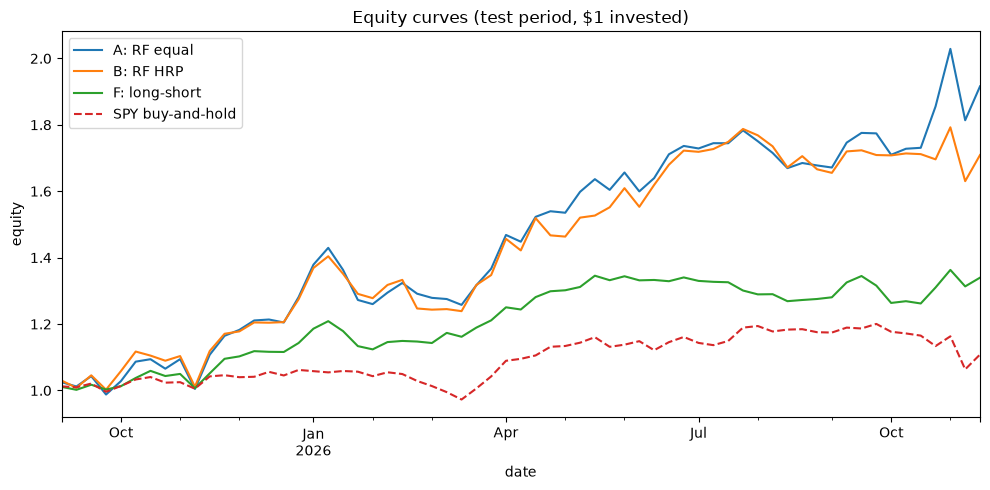

In [3]:
def equity(weekly: pd.DataFrame) -> pd.Series:
    eq = (1.0 + weekly.set_index('date')['ret']).cumprod()
    eq.index = pd.to_datetime(eq.index)
    return eq

fig, ax = plt.subplots()
for name, w in [('A: RF equal', w_a), ('B: RF HRP', w_b),
                ('F: long-short', w_ls)]:
    equity(w).plot(ax=ax, label=name)
# SPY equity over the same weeks.
spy_w = spy.sort_values('date').copy()
spy_w['next_spy_ret'] = spy_w['spy_ret'].shift(-1)
mask = spy_w['date'].isin(pd.to_datetime(test['date'].unique()))
spy_eq = (1.0 + spy_w.loc[mask, 'next_spy_ret'].dropna()).cumprod()
spy_eq.index = pd.to_datetime(spy_w.loc[mask, 'date'].iloc[:len(spy_eq)])
spy_eq.plot(ax=ax, label='SPY buy-and-hold', linestyle='--')
ax.set_title('Equity curves (test period, $1 invested)')
ax.set_ylabel('equity')
ax.legend()
plt.tight_layout()
plt.show()

## Rolling Sharpe and rolling returns (Strategy A)

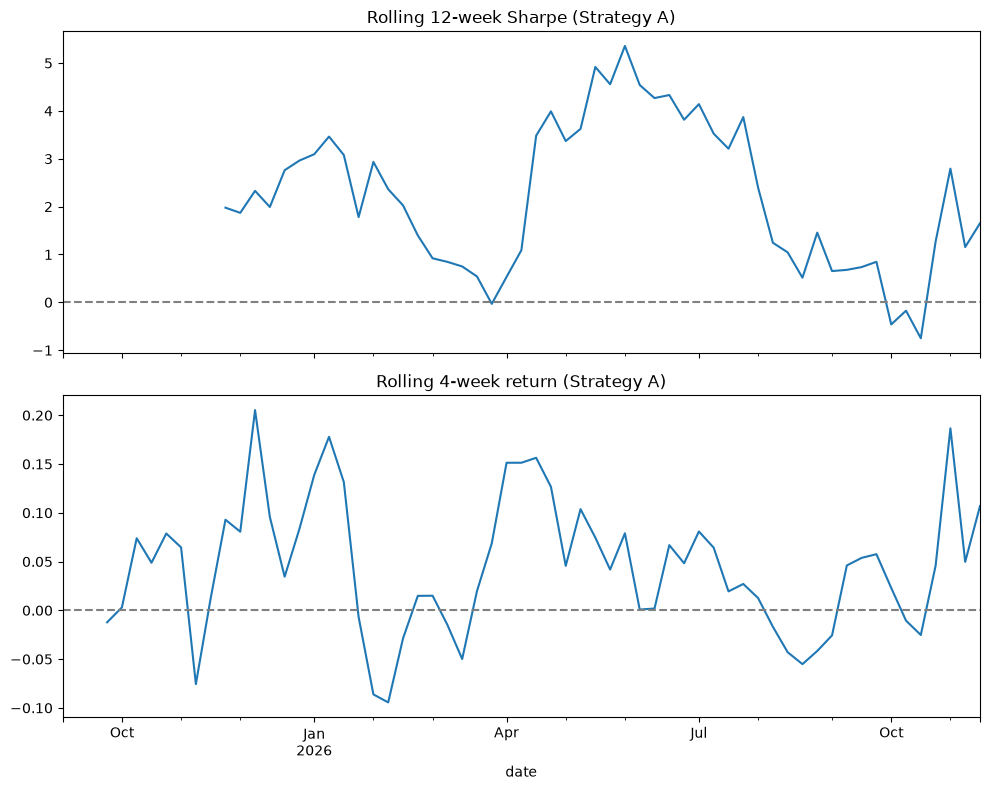

In [4]:
r = w_a.set_index('date')['ret']
roll_sharpe = r.rolling(12).mean() / r.rolling(12).std() * np.sqrt(52)
roll_ret4 = (1.0 + r).rolling(4).apply(lambda x: x.prod() - 1.0)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
roll_sharpe.plot(ax=ax1)
ax1.axhline(0, color='grey', linestyle='--')
ax1.set_title('Rolling 12-week Sharpe (Strategy A)')
roll_ret4.plot(ax=ax2)
ax2.axhline(0, color='grey', linestyle='--')
ax2.set_title('Rolling 4-week return (Strategy A)')
plt.tight_layout()
plt.show()

## Drawdown periods: what happened in the worst weeks?

The five worst weeks for Strategy A, with the holdings and the SPY
return that week -- was it a stock-picking failure or a market-wide
drop the strategy could not avoid?

In [5]:
worst = w_a.nsmallest(5, 'ret').copy()
spy_map = dict(zip(pd.to_datetime(spy['date']), spy['spy_ret'].shift(-1)))
worst['spy_next_ret'] = pd.to_datetime(worst['date']).map(spy_map)
print(worst[['date', 'ret', 'gross_ret', 'turnover',
             'spy_next_ret', 'holdings']].to_string(index=False))
eq = equity(w_a)
dd = (eq - eq.cummax()) / eq.cummax()
print(f"\nDeepest drawdown: {dd.min():.2%} in week of {dd.idxmin().date()}")

      date       ret  gross_ret  turnover  spy_next_ret              holdings
2026-11-09 -0.105952  -0.105736  0.432370     -0.085581 APTV,AKAM,APP,ARE,AMD
2025-11-10 -0.081962  -0.081650  0.624852     -0.019198  AMD,ARE,APP,ANET,APA
2026-01-26 -0.066464  -0.066355  0.219638     -0.001951 ALB,APP,AMAT,ANET,AMD
2025-09-29 -0.053161  -0.053057  0.208088     -0.024193   APP,AMAT,A,ALGN,ALB
2026-01-19 -0.046478  -0.046277  0.401118      0.003976 APP,AMD,AMAT,ANET,ARE

Deepest drawdown: -12.02% in week of 2026-03-16


## HRP vs equal-weight: weight evolution

HRP weights for the same top-5 picks, sampled across the test period,
vs the flat 20% equal weight. The effective number of holdings
(1 / sum(w^2)) shows how concentrated HRP gets.

In [6]:
from src.hrp import hrp_weights_for_week

weeks = sorted(test['date'].unique())
sample_weeks = weeks[:: max(1, len(weeks) // 6)][:6]
for d in sample_weeks:
    wk = test_rf[test_rf['date'] == d]
    picks = wk.nlargest(5, 'score')['ticker'].tolist()
    w = hrp_weights_for_week(prices, picks, pd.Timestamp(d))
    eff_n = 1.0 / float((w ** 2).sum())
    print(f"{pd.Timestamp(d).date()}: eff. N = {eff_n:.2f} | "
          + ", ".join(f"{t} {v:.2f}" for t, v in w.items()))

2025-09-08: eff. N = 3.55 | ANET 0.10, ACN 0.30, ALGN 0.07, AMD 0.14, GOOG 0.40
2025-11-17: eff. N = 3.82 | APP 0.14, ARE 0.21, ANET 0.13, AMD 0.11, AMAT 0.41
2026-01-26: eff. N = 4.11 | ALB 0.23, APP 0.12, AMAT 0.36, ANET 0.18, AMD 0.11
2026-04-06: eff. N = 4.42 | ARES 0.28, AKAM 0.10, APA 0.21, ARE 0.14, ADBE 0.27
2026-06-15: eff. N = 2.46 | ACN 0.10, APA 0.19, ABT 0.59, APP 0.03, ADBE 0.08
2026-08-24: eff. N = 3.62 | APTV 0.45, AMD 0.13, AMAT 0.16, APP 0.13, AKAM 0.14


## Turnover and cost decomposition (Strategy A)

Gross total return (no costs): +94.47%
Net total return:              +91.58%
Cost drag:                     +2.89% over 63 weeks
Average weekly turnover:       0.48
Exact-sim total costs paid:    $2,168 on $100,000 capital


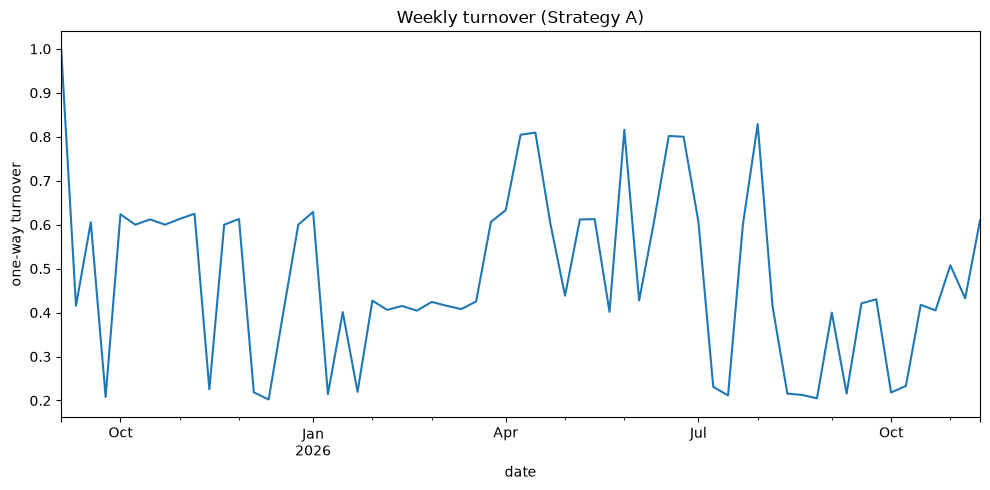

In [7]:
gross = (1.0 + w_a['gross_ret']).prod() - 1.0
net = m_a['total_return']
print(f"Gross total return (no costs): {gross:+.2%}")
print(f"Net total return:              {net:+.2%}")
print(f"Cost drag:                     {gross - net:+.2%} "
      f"over {len(w_a)} weeks")
print(f"Average weekly turnover:       {w_a['turnover'].mean():.2f}")
print(f"Exact-sim total costs paid:    ${m_exact['total_costs']:,.0f} "
      f"on $100,000 capital")
fig, ax = plt.subplots()
w_a.set_index('date')['turnover'].plot(ax=ax)
ax.set_title('Weekly turnover (Strategy A)')
ax.set_ylabel('one-way turnover')
plt.tight_layout()
plt.show()

## Long-short leg decomposition

Weekly returns of the long leg (top 5) and the short leg (bottom 5)
separately. A good long-short strategy makes money on both legs; if
only the long leg contributes, the shorts are mostly a hedge (and a
cost).

Long leg mean weekly return:  +1.1390%
Short leg mean weekly return: -0.1132% (profit = -return of the worst stocks)
Long leg win rate:  60.32%
Short leg win rate: 44.44%


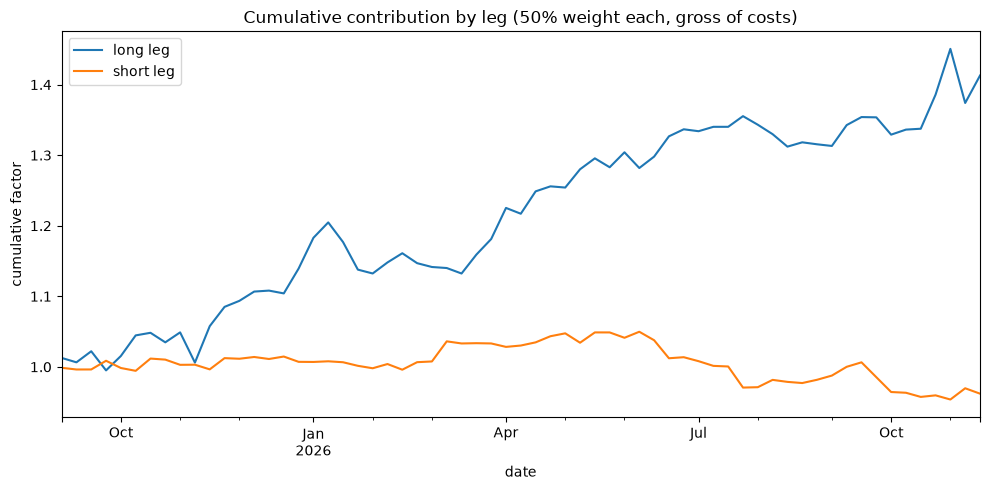

In [8]:
legs = []
for date, wk in test_rf.groupby('date', sort=True):
    longs = wk.nlargest(5, 'score')['next_ret'].mean()
    shorts = wk.nsmallest(5, 'score')['next_ret'].mean()
    legs.append({'date': date, 'long_leg': longs, 'short_leg': -shorts})
legs = pd.DataFrame(legs).set_index('date')
legs.index = pd.to_datetime(legs.index)
print(f"Long leg mean weekly return:  {legs['long_leg'].mean():+.4%}")
print(f"Short leg mean weekly return: {legs['short_leg'].mean():+.4%} "
      f"(profit = -return of the worst stocks)")
print(f"Long leg win rate:  {(legs['long_leg'] > 0).mean():.2%}")
print(f"Short leg win rate: {(legs['short_leg'] > 0).mean():.2%}")
fig, ax = plt.subplots()
((1.0 + 0.5 * legs).cumprod()).plot(ax=ax)
ax.set_title('Cumulative contribution by leg (50% weight each, gross of costs)')
ax.set_ylabel('cumulative factor')
ax.legend(['long leg', 'short leg'])
plt.tight_layout()
plt.show()